In [3]:
import pandas as pd
import os
import numpy as np
# import altair as alt
import plotly.express as px
import pkg_resources
import types

In [5]:
def get_imports():
    for name, val in globals().items():
        if isinstance(val, types.ModuleType):
            # Split ensures you get root package, 
            # not just imported function
            name = val.__name__.split(".")[0]

        elif isinstance(val, type):
            name = val.__module__.split(".")[0]

        # Some packages are weird and have different
        # imported names vs. system/pip names. Unfortunately,
        # there is no systematic way to get pip names from
        # a package's imported name. You'll have to add
        # exceptions to this list manually!
        poorly_named_packages = {
            "PIL": "Pillow",
            "sklearn": "scikit-learn"
        }
        if name in poorly_named_packages.keys():
            name = poorly_named_packages[name]

        yield name
imports = list(set(get_imports()))

# The only way I found to get the version of the root package
# from only the name of the package is to cross-check the names
# of installed packages vs. imported packages
requirements = []
for m in pkg_resources.working_set:
    if m.project_name in imports and m.project_name!="pip":
        requirements.append((m.project_name, m.version))

for r in requirements:
    print("{}=={}".format(*r))

numpy==1.26.4
pandas==2.2.2
plotly==5.22.0


In [63]:
path_original_data = os.path.join('..', 'Data', 'Original')
path_pre_measure = os.path.join('data', 'pre_measure.pkl')
path_pre_measure_stat = os.path.join('data', 'pre_measure_stat.pkl')
path_encoded_multipliers = os.path.join('data', 'encoded_multipliers.pkl')

In [21]:
size_df = pd.DataFrame(columns=['Filename', 'Size'])
for file_name in os.listdir(path_original_data):
    path = os.path.join(path_original_data, file_name)
    size = os.path.getsize(path)
    file_name1 = os.path.splitext(file_name)[0]
    list = [file_name1, size]
    size_df.loc[len(size_df)] = list
size_df

,Filename,Size
0,Ulysses,1586336
1,bbc_house,2248808
2,Vue_de_la_Buena_Vista,70296
3,Test,96
4,The_Picture_of_Dorian_Gray,465592
5,La_Jeunesse,26329
6,Around_the_World_in_Eighty_Days,403521
7,Anna_Karenina,2068079
8,bbc_peregrine_falcon,751800
9,decoded,192


In [23]:
df_measure = pd.read_pickle(path_pre_measure)

In [24]:
df_measure

,Filename,Method,Transformation,Type,Size,Cost,Time,OriFile_Size
0,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,1.153699,2068079
1,Anna_Karenina,SimpleCode,Decoding,.txt,1044246,0.000,0.120598,2068079
2,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,0.042246,2068079
3,Anna_Karenina,SimpleCode,Decoding,.txt,1044246,0.000,0.113129,2068079
4,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,0.042121,2068079
...,...,...,...,...,...,...,...,...
355,Vue_de_la_Buena_Vista,XORBasedCode,Decoding,.jpg,2035097,0.000,0.190041,70296
356,Vue_de_la_Buena_Vista,XORBasedCode,Encoding,.jpg,2035097,14996.800,0.091450,70296
357,Vue_de_la_Buena_Vista,XORBasedCode,Decoding,.jpg,2035097,0.000,0.110695,70296
358,Vue_de_la_Buena_Vista,XORBasedCode,Encoding,.jpg,2035097,14996.800,0.114664,70296


In [25]:
list = []
for filename in df_measure['Filename']:
    index = size_df.index[size_df['Filename'] == filename]
    size = size_df['Size'].iloc[index].values[0]
    list.append(size)
list[0:20]

[2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079,
 2068079]

In [26]:
df_measure['OriFile_Size']=list

In [27]:
df_measure

,Filename,Method,Transformation,Type,Size,Cost,Time,OriFile_Size
0,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,1.153699,2068079
1,Anna_Karenina,SimpleCode,Decoding,.txt,1044246,0.000,0.120598,2068079
2,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,0.042246,2068079
3,Anna_Karenina,SimpleCode,Decoding,.txt,1044246,0.000,0.113129,2068079
4,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,0.042121,2068079
...,...,...,...,...,...,...,...,...
355,Vue_de_la_Buena_Vista,XORBasedCode,Decoding,.jpg,2035097,0.000,0.190041,70296
356,Vue_de_la_Buena_Vista,XORBasedCode,Encoding,.jpg,2035097,14996.800,0.091450,70296
357,Vue_de_la_Buena_Vista,XORBasedCode,Decoding,.jpg,2035097,0.000,0.110695,70296
358,Vue_de_la_Buena_Vista,XORBasedCode,Encoding,.jpg,2035097,14996.800,0.114664,70296


In [28]:
df_measure.to_pickle(path_pre_measure)

In [29]:
df_agg = df_measure.groupby(['Filename', 'Method', 'Transformation', 'Type', 'OriFile_Size']).agg({'Size': ['mean', 'median', 'min', 'max', 'count', 'std'],'Time': ['mean', 'median', 'min', 'max', 'count', 'std'],'Cost': ['mean', 'median', 'min', 'max', 'count', 'std']}).reset_index()

In [30]:
df_agg

Filename        Method Transformation  Type  \
                                                                         
0                     Anna_Karenina    SimpleCode       Decoding  .txt   
1                     Anna_Karenina    SimpleCode       Encoding  .txt   
2                     Anna_Karenina  XORBasedCode       Decoding  .txt   
3                     Anna_Karenina  XORBasedCode       Encoding  .txt   
4   Around_the_World_in_Eighty_Days    SimpleCode       Decoding  .txt   
5   Around_the_World_in_Eighty_Days    SimpleCode       Encoding  .txt   
6   Around_the_World_in_Eighty_Days  XORBasedCode       Decoding  .txt   
7   Around_the_World_in_Eighty_Days  XORBasedCode       Encoding  .txt   
8                       La_Jeunesse    SimpleCode       Decoding  .jpg   
9                       La_Jeunesse    SimpleCode       Encoding  .jpg   
10                      La_Jeunesse  XORBasedCode       Decoding  .jpg   
11                      La_Jeunesse  XORBasedCode       Encoding  .jpg   
12       The_Picture_of_Dorian_Gray    SimpleCode       Decoding  .txt   
13       The_Picture_of_Dorian_Gray    SimpleCode       Encoding  .txt   
14       The_Picture_of_Dorian_Gray  XORBasedCode       Decoding  .txt   
15       The_Picture_of_Dorian_Gray  XORBasedCode       Encoding  .txt   
16               The_Republic_Plato    SimpleCode       Decoding  .txt   
17               The_Republic_Plato    SimpleCode       Encoding  .txt   
18               The_Republic_Plato  XORBasedCode       Decoding  .txt   
19               The_Republic_Plato  XORBasedCode       Encoding  .txt   
20                          Ulysses    SimpleCode       Decoding  .txt   
21                          Ulysses    SimpleCode       Encoding  .txt   
22                          Ulysses  XORBasedCode       Decoding  .txt   
23                          Ulysses  XORBasedCode       Encoding  .txt   
24            Vue_de_la_Buena_Vista    SimpleCode       Decoding  .jpg   
25            Vue_de_la_Buena_Vista    SimpleCode       Encoding  .jpg   
26            Vue_de_la_Buena_Vista  XORBasedCode       Decoding  .jpg   
27            Vue_de_la_Buena_Vista  XORBasedCode       Encoding  .jpg   
28                        bbc_house    SimpleCode       Decoding  .wav   
29                        bbc_house    SimpleCode       Encoding  .wav   
30                        bbc_house  XORBasedCode       Decoding  .wav   
31                        bbc_house  XORBasedCode       Encoding  .wav   
32             bbc_peregrine_falcon    SimpleCode       Decoding  .wav   
33             bbc_peregrine_falcon    SimpleCode       Encoding  .wav   
34             bbc_peregrine_falcon  XORBasedCode       Decoding  .wav   
35             bbc_peregrine_falcon  XORBasedCode       Encoding  .wav   

   OriFile_Size        Size                                        ...  \
                       mean      median       min       max count  ...   
0       2068079   1044246.0   1044246.0   1044246   1044246    10  ...   
1       2068079   1044246.0   1044246.0   1044246   1044246    10  ...   
2       2068079  59713316.0  59713316.0  59713316  59713316    10  ...   
3       2068079  59713316.0  59713316.0  59713316  59713316    10  ...   
4        403521   1044246.0   1044246.0   1044246   1044246    10  ...   
5        403521   1044246.0   1044246.0   1044246   1044246    10  ...   
6        403521  11652859.0  11652859.0  11652859  11652859    10  ...   
7        403521  11652859.0  11652859.0  11652859  11652859    10  ...   
8         26329    353395.0    353395.0    353395    353395    10  ...   
9         26329    353395.0    353395.0    353395    353395    10  ...   
10        26329    763094.0    763094.0    763094    763094    10  ...   
11        26329    763094.0    763094.0    763094    763094    10  ...   
12       465592   1044246.0   1044246.0   1044246   1044246    10  ...   
13       465592   1044246.0   1044246.0   1044246   1044246    10  ...   
14       465592  13442848.0  1

In [32]:
df_agg.to_pickle(path_pre_measure_stat)

In [33]:
df_stat = pd.read_pickle(path_pre_measure_stat)

In [34]:
cols = df_stat.columns.tolist()

In [35]:
cols[:-1]

[('Filename', ''),
 ('Method', ''),
 ('Transformation', ''),
 ('Type', ''),
 ('OriFile_Size', ''),
 ('Size', 'mean'),
 ('Size', 'median'),
 ('Size', 'min'),
 ('Size', 'max'),
 ('Size', 'count'),
 ('Size', 'std'),
 ('Time', 'mean'),
 ('Time', 'median'),
 ('Time', 'min'),
 ('Time', 'max'),
 ('Time', 'count'),
 ('Time', 'std'),
 ('Cost', 'mean'),
 ('Cost', 'median'),
 ('Cost', 'min'),
 ('Cost', 'max'),
 ('Cost', 'count')]

In [36]:
Filename = df_stat['Filename']
Method = df_stat['Method']
Transformation = df_stat['Transformation']
Type = df_stat['Type']
OriFile_Size = df_stat['OriFile_Size']
Mean_Size = df_stat['Size']['mean']
Median_Size = df_stat['Size']['median']
Min_Size = df_stat['Size']['min']
Max_Size = df_stat['Size']['max']
Std_Size = df_stat['Size']['std']
Mean_Time = df_stat['Time']['mean']
Median_Time = df_stat['Time']['median']
Min_Time = df_stat['Time']['min']
Max_Time = df_stat['Time']['max']
Std_Time = df_stat['Time']['std']
Mean_Cost = df_stat['Cost']['mean']
Median_Cost = df_stat['Cost']['median']
Min_Cost = df_stat['Cost']['min']
Max_Cost = df_stat['Cost']['max']
Std_Cost = df_stat['Cost']['std']

In [37]:
dict = {'Filename': Filename, 'Method': Method, 'Transformation': Transformation, 
        'Type': Type, 'OriFile_Size' : OriFile_Size, 'Mean_Size': Mean_Size, 'Median_Size': Median_Size, 
        'Min_Size': Min_Size, 'Max_Size': Max_Size, 'Std_Size': Std_Size, 
        'Mean_Time': Mean_Time, 'Median_Time': Median_Time, 'Min_Time': Min_Time, 
        'Max_Time': Max_Time, 'Std_Time': Std_Time, 'Mean_Cost': Mean_Cost, 
        'Median_Cost': Median_Cost, 'Min_Cost': Min_Cost, 'Max_Cost': Max_Cost, 
        'Std_Cost': Std_Cost}

In [38]:
df = pd.DataFrame(dict)

In [39]:
df

,Filename,Method,Transformation,Type,OriFile_Size,Mean_Size,Median_Size,Min_Size,Max_Size,Std_Size,Mean_Time,Median_Time,Min_Time,Max_Time,Std_Time,Mean_Cost,Median_Cost,Min_Cost,Max_Cost,Std_Cost
0,Anna_Karenina,SimpleCode,Decoding,.txt,2068079,1044246.0,1044246.0,1044246,1044246,0.0,0.111863,0.113448,0.101695,0.120598,0.006476,0.0000,0.0000,0.0000,0.0000,0.0
1,Anna_Karenina,SimpleCode,Encoding,.txt,2068079,1044246.0,1044246.0,1044246,1044246,0.0,0.154777,0.043508,0.041000,1.153699,0.350994,13364.4030,13364.4030,13364.4030,13364.4030,0.0
2,Anna_Karenina,XORBasedCode,Decoding,.txt,2068079,59713316.0,59713316.0,59713316,59713316,0.0,5.220238,5.573659,3.472771,6.918024,1.231655,0.0000,0.0000,0.0000,0.0000,0.0
3,Anna_Karenina,XORBasedCode,Encoding,.txt,2068079,59713316.0,59713316.0,59713316,59713316,0.0,3.314491,3.170029,2.942424,5.102380,0.634885,441190.4000,441190.4000,441190.4000,441190.4000,0.0
4,Around_the_World_in_Eighty_Days,SimpleCode,Decoding,.txt,403521,1044246.0,1044246.0,1044246,1044246,0.0,0.099295,0.098759,0.079083,0.122733,0.016723,0.0000,0.0000,0.0000,0.0000,0.0
5,Around_the_World_in_Eighty_Days,SimpleCode,Encoding,.txt,403521,1044246.0,1044246.0,1044246,1044246,0.0,0.126982,0.041005,0.034485,0.918646,0.278184,13364.4030,13364.4030,13364.4030,13364.4030,0.0
6,Around_the_World_in_Eighty_Days,XORBasedCode,Decoding,.txt,403521,11652859.0,11652859.0,11652859,11652859,0.0,0.960121,0.908934,0.604197,1.472252,0.332556,0.0000,0.0000,0.0000,0.0000,0.0
7,Around_the_World_in_Eighty_Days,XORBasedCode,Encoding,.txt,403521,11652859.0,11652859.0,11652859,11652859,0.0,0.637461,0.619506,0.505573,0.969580,0.129055,86084.8000,86084.8000,86084.8000,86084.8000,0.0
8,La_Jeunesse,SimpleCode,Decoding,.jpg,26329,353395.0,353395.0,353395,353395,0.0,0.035979,0.037403,0.026067,0.044127,0.005858,0.0000,0.0000,0.0000,0.0000,0.0
9,La_Jeunesse,SimpleCode,Encoding,.jpg,26329,353395.0,353395.0,353395,353395,0.0,0.044609,0.014459,0.011331,0.315333,0.095164,4522.7975,4522.7975,4522.7975,4522.7975,0.0


In [40]:
df.to_pickle(path_pre_measure_stat)

In [41]:
df = pd.read_pickle(path_pre_measure_stat)

In [42]:
df

,Filename,Method,Transformation,Type,OriFile_Size,Mean_Size,Median_Size,Min_Size,Max_Size,Std_Size,Mean_Time,Median_Time,Min_Time,Max_Time,Std_Time,Mean_Cost,Median_Cost,Min_Cost,Max_Cost,Std_Cost
0,Anna_Karenina,SimpleCode,Decoding,.txt,2068079,1044246.0,1044246.0,1044246,1044246,0.0,0.111863,0.113448,0.101695,0.120598,0.006476,0.0000,0.0000,0.0000,0.0000,0.0
1,Anna_Karenina,SimpleCode,Encoding,.txt,2068079,1044246.0,1044246.0,1044246,1044246,0.0,0.154777,0.043508,0.041000,1.153699,0.350994,13364.4030,13364.4030,13364.4030,13364.4030,0.0
2,Anna_Karenina,XORBasedCode,Decoding,.txt,2068079,59713316.0,59713316.0,59713316,59713316,0.0,5.220238,5.573659,3.472771,6.918024,1.231655,0.0000,0.0000,0.0000,0.0000,0.0
3,Anna_Karenina,XORBasedCode,Encoding,.txt,2068079,59713316.0,59713316.0,59713316,59713316,0.0,3.314491,3.170029,2.942424,5.102380,0.634885,441190.4000,441190.4000,441190.4000,441190.4000,0.0
4,Around_the_World_in_Eighty_Days,SimpleCode,Decoding,.txt,403521,1044246.0,1044246.0,1044246,1044246,0.0,0.099295,0.098759,0.079083,0.122733,0.016723,0.0000,0.0000,0.0000,0.0000,0.0
5,Around_the_World_in_Eighty_Days,SimpleCode,Encoding,.txt,403521,1044246.0,1044246.0,1044246,1044246,0.0,0.126982,0.041005,0.034485,0.918646,0.278184,13364.4030,13364.4030,13364.4030,13364.4030,0.0
6,Around_the_World_in_Eighty_Days,XORBasedCode,Decoding,.txt,403521,11652859.0,11652859.0,11652859,11652859,0.0,0.960121,0.908934,0.604197,1.472252,0.332556,0.0000,0.0000,0.0000,0.0000,0.0
7,Around_the_World_in_Eighty_Days,XORBasedCode,Encoding,.txt,403521,11652859.0,11652859.0,11652859,11652859,0.0,0.637461,0.619506,0.505573,0.969580,0.129055,86084.8000,86084.8000,86084.8000,86084.8000,0.0
8,La_Jeunesse,SimpleCode,Decoding,.jpg,26329,353395.0,353395.0,353395,353395,0.0,0.035979,0.037403,0.026067,0.044127,0.005858,0.0000,0.0000,0.0000,0.0000,0.0
9,La_Jeunesse,SimpleCode,Encoding,.jpg,26329,353395.0,353395.0,353395,353395,0.0,0.044609,0.014459,0.011331,0.315333,0.095164,4522.7975,4522.7975,4522.7975,4522.7975,0.0


In [43]:
Filename = []
for name in df['Filename']:
    if name not in Filename:
        Filename.append(name)
Filename

['Anna_Karenina',
 'Around_the_World_in_Eighty_Days',
 'La_Jeunesse',
 'The_Picture_of_Dorian_Gray',
 'The_Republic_Plato',
 'Ulysses',
 'Vue_de_la_Buena_Vista',
 'bbc_house',
 'bbc_peregrine_falcon']

In [44]:
df_agg = df.groupby(['Filename', 'Method', 'Type', 'OriFile_Size']).agg({'Mean_Size': ['sum'],'Mean_Time': ['sum'],'Mean_Cost': ['sum']}).reset_index()

In [45]:
df_agg

,Filename,Method,Type,OriFile_Size,Mean_Size,Mean_Time,Mean_Cost
,,,,,sum,sum,sum
0,Anna_Karenina,SimpleCode,.txt,2068079,2088492.0,0.266640,13364.4030
1,Anna_Karenina,XORBasedCode,.txt,2068079,119426632.0,8.534729,441190.4000
2,Around_the_World_in_Eighty_Days,SimpleCode,.txt,403521,2088492.0,0.226277,13364.4030
3,Around_the_World_in_Eighty_Days,XORBasedCode,.txt,403521,23305718.0,1.597582,86084.8000
4,La_Jeunesse,SimpleCode,.jpg,26329,706790.0,0.080588,4522.7975
5,La_Jeunesse,XORBasedCode,.jpg,26329,1526188.0,0.102217,5616.8000
6,The_Picture_of_Dorian_Gray,SimpleCode,.txt,465592,2088492.0,0.244948,13364.4030
7,The_Picture_of_Dorian_Gray,XORBasedCode,.txt,465592,26885696.0,1.717028,99326.4000
8,The_Republic_Plato,SimpleCode,.txt,1243940,2088492.0,0.240779,13364.4030


In [46]:
Filename = df_agg['Filename']
Method = df_agg['Method']
Type = df_agg['Type']
OriFile_Size = df_agg['OriFile_Size']
Sum_Mean_Size = df_agg['Mean_Size']['sum']
Sum_Mean_Time = df_agg['Mean_Time']['sum']
Sum_Mean_Cost = df_agg['Mean_Cost']['sum']

In [47]:
dict = {'Filename': Filename, 'Method': Method, 
        'Type': Type, 'OriFile_Size' : OriFile_Size, 'Sum_Mean_Size': Sum_Mean_Size, 
        'Sum_Mean_Time': Sum_Mean_Time,
        'Sum_Mean_Cost': Sum_Mean_Cost}

In [48]:
df_agg_summary = pd.DataFrame(dict)

In [49]:
df_agg_summary

,Filename,Method,Type,OriFile_Size,Sum_Mean_Size,Sum_Mean_Time,Sum_Mean_Cost
0,Anna_Karenina,SimpleCode,.txt,2068079,2088492.0,0.266640,13364.4030
1,Anna_Karenina,XORBasedCode,.txt,2068079,119426632.0,8.534729,441190.4000
2,Around_the_World_in_Eighty_Days,SimpleCode,.txt,403521,2088492.0,0.226277,13364.4030
3,Around_the_World_in_Eighty_Days,XORBasedCode,.txt,403521,23305718.0,1.597582,86084.8000
4,La_Jeunesse,SimpleCode,.jpg,26329,706790.0,0.080588,4522.7975
5,La_Jeunesse,XORBasedCode,.jpg,26329,1526188.0,0.102217,5616.8000
6,The_Picture_of_Dorian_Gray,SimpleCode,.txt,465592,2088492.0,0.244948,13364.4030
7,The_Picture_of_Dorian_Gray,XORBasedCode,.txt,465592,26885696.0,1.717028,99326.4000
8,The_Republic_Plato,SimpleCode,.txt,1243940,2088492.0,0.240779,13364.4030
9,The_Republic_Plato,XORBasedCode,.txt,1243940,71839466.0,4.912604,265373.6000


In [53]:
path_original_data = os.path.join('..', 'Data', 'Original')
path_encoded_dna = os.path.join('..', 'Data', 'Encoded_DNA')
path_decoded_dna = os.path.join('..', 'Data', 'Decoded_DNA')

encoding_method = ["Repetition Code", "Simple Code", "2D" "XOR-Based Code"]

df_result = pd.DataFrame(columns=['Filename', 'Method', 'Type', 'Similarity'])

for string_file in os.listdir(path_original_data):
    if not os.path.isfile(os.path.join(path_original_data, string_file)):
        continue

    string_file_no_extension = os.path.splitext(string_file)[0]
    file_extension = os.path.splitext(string_file)[1]
    before_encoding = string_file_no_extension + '.npy'
    bit_path = os.path.join(path_encoded_dna, before_encoding)
    original_bit = np.load(bit_path)
    for em in encoding_method:
        if em == 'Simple Code':
            file_name = string_file_no_extension + '_simple.npy'
        elif em == 'Repetition Code':
            file_name = string_file_no_extension + '_repetition.npy'
        elif em == 'The 2D Code':
            file_name = string_file_no_extension + '_2d.npy'
        elif em == 'XOR-Based Code':
            file_name = string_file_no_extension + '_xor.npy'
        path_decoded = os.path.join(path_decoded_dna, file_name)
        bit_decoded = np.load(path_decoded)

        if len(bit_decoded) == len(original_bit):
            i = 0
            status = 'Same'
            while i < len(bit_decoded) and status == 'Same':
                if bit_decoded[i] == original_bit[i]:
                    status = 'Same'
                else:
                    status = 'Different'
                i += 1
        else:
            status = 'Different'

        list = [string_file_no_extension, em, file_extension, status]
        df_result.loc[len(df_result)] = list

In [54]:
df_result

,Filename,Method,Type,Similarity
0,Ulysses,Repetition Code,.txt,Different
1,Ulysses,Simple Code,.txt,Different
2,Ulysses,2DXOR-Based Code,.txt,Different
3,bbc_house,Repetition Code,.wav,Different
4,bbc_house,Simple Code,.wav,Different
5,bbc_house,2DXOR-Based Code,.wav,Different
6,Vue_de_la_Buena_Vista,Repetition Code,.jpg,Different
7,Vue_de_la_Buena_Vista,Simple Code,.jpg,Different
8,Vue_de_la_Buena_Vista,2DXOR-Based Code,.jpg,Different
9,The_Picture_of_Dorian_Gray,Repetition Code,.txt,Different


In [55]:
result = pd.concat([df_agg_summary, df_result['Similarity']], axis=1, join="inner")

In [56]:
result

,Filename,Method,Type,OriFile_Size,Sum_Mean_Size,Sum_Mean_Time,Sum_Mean_Cost,Similarity
0,Anna_Karenina,SimpleCode,.txt,2068079,2088492.0,0.266640,13364.4030,Different
1,Anna_Karenina,XORBasedCode,.txt,2068079,119426632.0,8.534729,441190.4000,Different
2,Around_the_World_in_Eighty_Days,SimpleCode,.txt,403521,2088492.0,0.226277,13364.4030,Different
3,Around_the_World_in_Eighty_Days,XORBasedCode,.txt,403521,23305718.0,1.597582,86084.8000,Different
4,La_Jeunesse,SimpleCode,.jpg,26329,706790.0,0.080588,4522.7975,Different
5,La_Jeunesse,XORBasedCode,.jpg,26329,1526188.0,0.102217,5616.8000,Different
6,The_Picture_of_Dorian_Gray,SimpleCode,.txt,465592,2088492.0,0.244948,13364.4030,Different
7,The_Picture_of_Dorian_Gray,XORBasedCode,.txt,465592,26885696.0,1.717028,99326.4000,Different
8,The_Republic_Plato,SimpleCode,.txt,1243940,2088492.0,0.240779,13364.4030,Different
9,The_Republic_Plato,XORBasedCode,.txt,1243940,71839466.0,4.912604,265373.6000,Different


In [57]:
result.to_pickle(path_pre_measure_stat)

In [58]:
df_measure_stat = pd.read_pickle(path_pre_measure_stat)

In [59]:
df_measure_stat

,Filename,Method,Type,OriFile_Size,Sum_Mean_Size,Sum_Mean_Time,Sum_Mean_Cost,Similarity
0,Anna_Karenina,SimpleCode,.txt,2068079,2088492.0,0.266640,13364.4030,Different
1,Anna_Karenina,XORBasedCode,.txt,2068079,119426632.0,8.534729,441190.4000,Different
2,Around_the_World_in_Eighty_Days,SimpleCode,.txt,403521,2088492.0,0.226277,13364.4030,Different
3,Around_the_World_in_Eighty_Days,XORBasedCode,.txt,403521,23305718.0,1.597582,86084.8000,Different
4,La_Jeunesse,SimpleCode,.jpg,26329,706790.0,0.080588,4522.7975,Different
5,La_Jeunesse,XORBasedCode,.jpg,26329,1526188.0,0.102217,5616.8000,Different
6,The_Picture_of_Dorian_Gray,SimpleCode,.txt,465592,2088492.0,0.244948,13364.4030,Different
7,The_Picture_of_Dorian_Gray,XORBasedCode,.txt,465592,26885696.0,1.717028,99326.4000,Different
8,The_Republic_Plato,SimpleCode,.txt,1243940,2088492.0,0.240779,13364.4030,Different
9,The_Republic_Plato,XORBasedCode,.txt,1243940,71839466.0,4.912604,265373.6000,Different


In [60]:
df_encoding = df_measure[df_measure['Transformation']=='Encoding']

In [61]:
df_encoding = df_encoding.reset_index()

In [62]:
df_encoding['Multipliers'] = df_encoding['Size']/df_encoding['OriFile_Size']

In [64]:
df_encoding.to_pickle(path_encoded_multipliers)

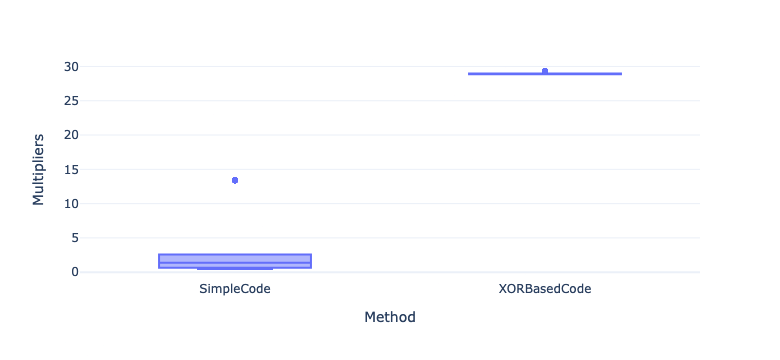

In [70]:
'''
chart = alt.Chart(df_encoding).mark_boxplot(extent='min-max').encode(
            alt.X('Method:N', title='Method', axis=alt.Axis(labelAngle=-45)),
            alt.Y('Multipliers:Q', title='Multipliers')
        ).properties(title='Multipliers ')
'''
chart = px.box(df_encoding, x='Method', y='Multipliers',
               template='plotly_white')
chart

In [38]:
df_measure = pd.read_pickle(r"data/pre_measure1.pkl")

In [39]:
df_measure

,Filename,Method,Size,Cost,Type,Similarity,Ori_FileSize
0,Anna_Karenina,Simple Code,1044246,13364.4030,.txt,Different,2068079
1,Anna_Karenina,XOR-Based Code,59713316,441190.4000,.txt,Same,2068079
2,Around_the_World_in_Eighty_Days,Simple Code,1044246,13364.4030,.txt,Different,403521
3,Around_the_World_in_Eighty_Days,XOR-Based Code,11652859,86084.8000,.txt,Same,403521
4,bbc_house,Simple Code,1044246,13364.4030,.wav,Different,2248808
5,bbc_house,XOR-Based Code,65725941,479745.6000,.wav,Same,2248808
6,bbc_peregrine_falcon,Simple Code,1044246,13364.4030,.wav,Different,751800
7,bbc_peregrine_falcon,XOR-Based Code,22055171,160384.0000,.wav,Same,751800
8,La_Jeunesse,Simple Code,353395,4522.7975,.jpg,Different,26329
9,La_Jeunesse,XOR-Based Code,763094,5616.8000,.jpg,Same,26329


In [40]:
df_measure['Multipliers'] = df_measure['Size']/df_measure['Ori_FileSize']

In [41]:
df_measure

,Filename,Method,Size,Cost,Type,Similarity,Ori_FileSize,Multipliers
0,Anna_Karenina,Simple Code,1044246,13364.4030,.txt,Different,2068079,0.504935
1,Anna_Karenina,XOR-Based Code,59713316,441190.4000,.txt,Same,2068079,28.873808
2,Around_the_World_in_Eighty_Days,Simple Code,1044246,13364.4030,.txt,Different,403521,2.587836
3,Around_the_World_in_Eighty_Days,XOR-Based Code,11652859,86084.8000,.txt,Same,403521,28.877949
4,bbc_house,Simple Code,1044246,13364.4030,.wav,Different,2248808,0.464355
5,bbc_house,XOR-Based Code,65725941,479745.6000,.wav,Same,2248808,29.227013
6,bbc_peregrine_falcon,Simple Code,1044246,13364.4030,.wav,Different,751800,1.388994
7,bbc_peregrine_falcon,XOR-Based Code,22055171,160384.0000,.wav,Same,751800,29.336487
8,La_Jeunesse,Simple Code,353395,4522.7975,.jpg,Different,26329,13.422272
9,La_Jeunesse,XOR-Based Code,763094,5616.8000,.jpg,Same,26329,28.983023


In [42]:
df_time = pd.read_pickle(r"data/pre_measure_time2.pkl")

In [43]:
df_time

,Filename,Method,Transformation,Time,Type
0,Anna_Karenina,Simple Code,Encoding,1.153699,.txt
1,Anna_Karenina,Simple Code,Decoding,0.120598,.txt
2,Anna_Karenina,XOR-Based Code,Encoding,5.102380,.txt
3,Anna_Karenina,XOR-Based Code,Decoding,4.063625,.txt
4,Around_the_World_in_Eighty_Days,Simple Code,Encoding,0.918646,.txt
...,...,...,...,...,...
355,Ulysses,XOR-Based Code,Decoding,2.766728,.txt
356,Vue_de_la_Buena_Vista,Simple Code,Encoding,0.035593,.jpg
357,Vue_de_la_Buena_Vista,Simple Code,Decoding,0.097582,.jpg
358,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,0.114664,.jpg


In [44]:
df_avg_time = df_time.groupby(['Filename', 'Method', 'Type', 'Transformation']).agg({'Time': ['mean']}).reset_index()

In [45]:
df_avg_time

,Filename,Method,Type,Transformation,Time
,,,,,mean
0,Anna_Karenina,Simple Code,.txt,Decoding,0.111863
1,Anna_Karenina,Simple Code,.txt,Encoding,0.154777
2,Anna_Karenina,XOR-Based Code,.txt,Decoding,5.220238
3,Anna_Karenina,XOR-Based Code,.txt,Encoding,3.314491
4,Around_the_World_in_Eighty_Days,Simple Code,.txt,Decoding,0.099295
5,Around_the_World_in_Eighty_Days,Simple Code,.txt,Encoding,0.126982
6,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,Decoding,0.960121
7,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,Encoding,0.637461
8,La_Jeunesse,Simple Code,.jpg,Decoding,0.035979


In [46]:
Filename = df_avg_time['Filename']
Method = df_avg_time['Method']
Transformation = df_avg_time['Transformation']
Type = df_avg_time['Type']
Mean_Time = df_avg_time['Time']['mean']

In [47]:
dict = {'Filename': Filename, 'Method': Method, 'Transformation': Transformation, 
        'Type': Type, 'Mean_Time': Mean_Time}

In [48]:
df_time_avg = pd.DataFrame(dict)

In [49]:
df_time_avg

,Filename,Method,Transformation,Type,Mean_Time
0,Anna_Karenina,Simple Code,Decoding,.txt,0.111863
1,Anna_Karenina,Simple Code,Encoding,.txt,0.154777
2,Anna_Karenina,XOR-Based Code,Decoding,.txt,5.220238
3,Anna_Karenina,XOR-Based Code,Encoding,.txt,3.314491
4,Around_the_World_in_Eighty_Days,Simple Code,Decoding,.txt,0.099295
5,Around_the_World_in_Eighty_Days,Simple Code,Encoding,.txt,0.126982
6,Around_the_World_in_Eighty_Days,XOR-Based Code,Decoding,.txt,0.960121
7,Around_the_World_in_Eighty_Days,XOR-Based Code,Encoding,.txt,0.637461
8,La_Jeunesse,Simple Code,Decoding,.jpg,0.035979
9,La_Jeunesse,Simple Code,Encoding,.jpg,0.044609


In [50]:
df_agg_time = df_time_avg.groupby(['Filename', 'Method', 'Type']).agg({'Mean_Time': ['sum']}).reset_index()

In [51]:
Filename = df_agg_time['Filename']
Method = df_agg_time['Method']
Type = df_agg_time['Type']
Sum_Mean_Time = df_agg_time['Mean_Time']['sum']

In [52]:
dict = {'Filename': Filename, 'Method': Method, 
        'Type': Type, 'Sum_Mean_Time': Sum_Mean_Time}

In [53]:
df_agg_time_summary = pd.DataFrame(dict)

In [54]:
df_agg_time_summary

,Filename,Method,Type,Sum_Mean_Time
0,Anna_Karenina,Simple Code,.txt,0.266640
1,Anna_Karenina,XOR-Based Code,.txt,8.534729
2,Around_the_World_in_Eighty_Days,Simple Code,.txt,0.226277
3,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,1.597582
4,La_Jeunesse,Simple Code,.jpg,0.080588
5,La_Jeunesse,XOR-Based Code,.jpg,0.102217
6,The_Picture_of_Dorian_Gray,Simple Code,.txt,0.244948
7,The_Picture_of_Dorian_Gray,XOR-Based Code,.txt,1.717028
8,The_Republic_Plato,Simple Code,.txt,0.240779
9,The_Republic_Plato,XOR-Based Code,.txt,4.912604


In [55]:
df_merge_sum = pd.merge(df_measure, df_agg_time_summary, on = ['Filename', 'Method', 'Type'], how = 'inner')

In [56]:
df_merge_sum['Sum_Size'] = 2*df_merge_sum['Size']

In [57]:
df_merge_sum

,Filename,Method,Size,Cost,Type,Similarity,Ori_FileSize,Multipliers,Sum_Mean_Time,Sum_Size
0,Anna_Karenina,Simple Code,1044246,13364.4030,.txt,Different,2068079,0.504935,0.266640,2088492
1,Anna_Karenina,XOR-Based Code,59713316,441190.4000,.txt,Same,2068079,28.873808,8.534729,119426632
2,Around_the_World_in_Eighty_Days,Simple Code,1044246,13364.4030,.txt,Different,403521,2.587836,0.226277,2088492
3,Around_the_World_in_Eighty_Days,XOR-Based Code,11652859,86084.8000,.txt,Same,403521,28.877949,1.597582,23305718
4,bbc_house,Simple Code,1044246,13364.4030,.wav,Different,2248808,0.464355,0.226153,2088492
5,bbc_house,XOR-Based Code,65725941,479745.6000,.wav,Same,2248808,29.227013,9.091302,131451882
6,bbc_peregrine_falcon,Simple Code,1044246,13364.4030,.wav,Different,751800,1.388994,0.234377,2088492
7,bbc_peregrine_falcon,XOR-Based Code,22055171,160384.0000,.wav,Same,751800,29.336487,2.690585,44110342
8,La_Jeunesse,Simple Code,353395,4522.7975,.jpg,Different,26329,13.422272,0.080588,706790
9,La_Jeunesse,XOR-Based Code,763094,5616.8000,.jpg,Same,26329,28.983023,0.102217,1526188


In [74]:
Filename = df_merge_sum['Filename']
Method = df_merge_sum['Method']
Type = df_merge_sum['Type']
Sum_Mean_Time = df_merge_sum['Sum_Mean_Time']
Sum_Size = df_merge_sum['Sum_Size']
Sum_Cost = df_merge_sum['Cost']
Encoding_Multipliers = df_merge_sum['Multipliers']
Similarity = df_merge_sum['Similarity']

dict = {'Filename': Filename, 'Method': Method, 
        'Type': Type, 'Sum_Mean_Time': Sum_Mean_Time, 'Sum_Size': Sum_Size, 'Sum_Cost': Sum_Cost, 
        'Encoding_Multipliers': Encoding_Multipliers, 'Similarity': Similarity}

df_premeasure_sum = pd.DataFrame(dict)
df_premeasure_sum

,Filename,Method,Type,Sum_Mean_Time,Sum_Size,Sum_Cost,Encoding_Multipliers,Similarity
0,Anna_Karenina,Simple Code,.txt,0.266640,2088492,13364.4030,0.504935,Different
1,Anna_Karenina,XOR-Based Code,.txt,8.534729,119426632,441190.4000,28.873808,Same
2,Around_the_World_in_Eighty_Days,Simple Code,.txt,0.226277,2088492,13364.4030,2.587836,Different
3,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,1.597582,23305718,86084.8000,28.877949,Same
4,bbc_house,Simple Code,.wav,0.226153,2088492,13364.4030,0.464355,Different
5,bbc_house,XOR-Based Code,.wav,9.091302,131451882,479745.6000,29.227013,Same
6,bbc_peregrine_falcon,Simple Code,.wav,0.234377,2088492,13364.4030,1.388994,Different
7,bbc_peregrine_falcon,XOR-Based Code,.wav,2.690585,44110342,160384.0000,29.336487,Same
8,La_Jeunesse,Simple Code,.jpg,0.080588,706790,4522.7975,13.422272,Different
9,La_Jeunesse,XOR-Based Code,.jpg,0.102217,1526188,5616.8000,28.983023,Same


In [75]:
df_premeasure_sum.to_pickle('data/pre_measure_stat_sum1.pkl')

In [60]:
Filename = df_merge_sum['Filename']
Method = df_merge_sum['Method']
Type = df_merge_sum['Type']
Multipliers = df_merge_sum['Multipliers']

dict = {'Filename': Filename, 'Method': Method, 
        'Type': Type, 'Multipliers': Multipliers}

df_multipliers_new = pd.DataFrame(dict)

In [61]:
df_multipliers_new 

,Filename,Method,Type,Multipliers
0,Anna_Karenina,Simple Code,.txt,0.504935
1,Anna_Karenina,XOR-Based Code,.txt,28.873808
2,Around_the_World_in_Eighty_Days,Simple Code,.txt,2.587836
3,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,28.877949
4,bbc_house,Simple Code,.wav,0.464355
5,bbc_house,XOR-Based Code,.wav,29.227013
6,bbc_peregrine_falcon,Simple Code,.wav,1.388994
7,bbc_peregrine_falcon,XOR-Based Code,.wav,29.336487
8,La_Jeunesse,Simple Code,.jpg,13.422272
9,La_Jeunesse,XOR-Based Code,.jpg,28.983023


In [62]:
df_multipliers_new.to_pickle('data/encoded_multipliers1.pkl')

In [22]:
df_multipliers = pd.read_pickle("data/encoded_multipliers.pkl")

In [23]:
df_multipliers

,index,Filename,Method,Transformation,Size,Cost,Time,Type,OriFile_Size,Multipliers
0,0,Anna_Karenina,Repetition Code,Encoding,48555234,48555234,24.537284,.txt,2068079,23.478423
1,2,Anna_Karenina,Simple Code,Encoding,1031274,1031274,1.087373,.txt,2068079,0.498663
2,4,Anna_Karenina,XOR-Based Code,Encoding,58610340,58610340,2.004188,.txt,2068079,28.340474
3,6,Around_the_World_in_Eighty_Days,Repetition Code,Encoding,9469746,9469746,3.853203,.txt,403521,23.467790
4,8,Around_the_World_in_Eighty_Days,Simple Code,Encoding,1031274,1031274,1.054477,.txt,403521,2.555689
...,...,...,...,...,...,...,...,...,...,...
265,530,Ulysses,Simple Code,Encoding,1031274,1031274,1.184595,.txt,1586336,0.650098
266,532,Ulysses,XOR-Based Code,Encoding,44966269,44966269,4.294873,.txt,1586336,28.345993
267,534,Vue_de_la_Buena_Vista,Repetition Code,Encoding,1668186,1668186,2.475071,.jpg,70296,23.730881
268,536,Vue_de_la_Buena_Vista,Simple Code,Encoding,931581,931581,1.268053,.jpg,70296,13.252262


In [24]:
df_measure_sum = pd.read_pickle("data/pre_measure_stat_sum.pkl")
df_measure_sum

,Filename,Method,Type,OriFile_Size,Sum_Mean_Size,Sum_Mean_Time,Sum_Mean_Cost,Similarity
0,Anna_Karenina,Repetition Code,.txt,2068079,48555362.0,109.447811,48555234.0,Different
1,Anna_Karenina,Simple Code,.txt,2068079,1654058.0,1.414864,1653930.0,Different
2,Anna_Karenina,XOR-Based Code,.txt,2068079,75155100.0,9.403734,75154972.0,Same
3,Around_the_World_in_Eighty_Days,Repetition Code,.txt,403521,9469874.0,22.224403,9469746.0,Different
4,Around_the_World_in_Eighty_Days,Simple Code,.txt,403521,1654058.0,1.413229,1653930.0,Different
5,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,403521,14665943.0,2.291381,14665815.0,Same
6,La_Jeunesse,Repetition Code,.jpg,26329,624206.0,1.332081,624078.0,Different
7,La_Jeunesse,Simple Code,.jpg,26329,559853.0,0.470821,559725.0,Different
8,La_Jeunesse,XOR-Based Code,.jpg,26329,959812.0,0.120771,959684.0,Same
9,The_Picture_of_Dorian_Gray,Repetition Code,.txt,465592,10934714.0,24.677164,10934586.0,Different


In [25]:
df_measure = pd.read_pickle("data/pre_measure.pkl")
df_measure

,Filename,Method,Transformation,Size,Cost,Time,Type,OriFile_Size
0,Anna_Karenina,Repetition Code,Encoding,48555234,48555234,24.537284,.txt,2068079
1,Anna_Karenina,Repetition Code,Decoding,128,0,69.430668,.txt,2068079
2,Anna_Karenina,Simple Code,Encoding,1031274,1031274,1.087373,.txt,2068079
3,Anna_Karenina,Simple Code,Decoding,622784,622656,0.113236,.txt,2068079
4,Anna_Karenina,XOR-Based Code,Encoding,58610340,58610340,2.004188,.txt,2068079
...,...,...,...,...,...,...,...,...
535,Vue_de_la_Buena_Vista,Repetition Code,Decoding,128,0,2.335622,.jpg,70296
536,Vue_de_la_Buena_Vista,Simple Code,Encoding,931581,931581,1.268053,.jpg,70296
537,Vue_de_la_Buena_Vista,Simple Code,Decoding,562592,562464,0.148494,.jpg,70296
538,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,1997605,1997605,0.068561,.jpg,70296


In [66]:
df_merge_detail = pd.merge(df_time, df_measure, on = ['Filename', 'Method', 'Type'], how = 'inner')

In [67]:
df_merge_detail

,Filename,Method,Transformation,Time,Type,Size,Cost,Similarity,Ori_FileSize,Multipliers
0,Anna_Karenina,Simple Code,Encoding,1.153699,.txt,1044246,13364.403,Different,2068079,0.504935
1,Anna_Karenina,Simple Code,Decoding,0.120598,.txt,1044246,13364.403,Different,2068079,0.504935
2,Anna_Karenina,Simple Code,Encoding,0.042246,.txt,1044246,13364.403,Different,2068079,0.504935
3,Anna_Karenina,Simple Code,Decoding,0.113129,.txt,1044246,13364.403,Different,2068079,0.504935
4,Anna_Karenina,Simple Code,Encoding,0.042121,.txt,1044246,13364.403,Different,2068079,0.504935
...,...,...,...,...,...,...,...,...,...,...
355,Vue_de_la_Buena_Vista,XOR-Based Code,Decoding,0.190041,.jpg,2035097,14996.800,Same,70296,28.950395
356,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,0.091450,.jpg,2035097,14996.800,Same,70296,28.950395
357,Vue_de_la_Buena_Vista,XOR-Based Code,Decoding,0.110695,.jpg,2035097,14996.800,Same,70296,28.950395
358,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,0.114664,.jpg,2035097,14996.800,Same,70296,28.950395


In [72]:
Filename = df_merge_detail['Filename']
Method = df_merge_detail['Method']
Type = df_merge_detail['Type']
Transformation = df_merge_detail['Transformation']
Size = df_merge_detail['Size']
Cost = df_merge_detail['Cost']
Time = df_merge_detail['Time']
OriFile_Size = df_merge_detail['Ori_FileSize']

dict = {'Filename': Filename, 'Method': Method, 'Transformation': Transformation, 'Type': Type, 'Size': Size, 'Cost': Cost,
       'Time': Time, 'OriFile_Size':OriFile_Size }

df_merge_detail_new = pd.DataFrame(dict)
df_merge_detail_new.loc[df_merge_detail_new['Transformation'] == 'Decoding', 'Cost'] = 0
df_merge_detail_new

,Filename,Method,Transformation,Type,Size,Cost,Time,OriFile_Size
0,Anna_Karenina,Simple Code,Encoding,.txt,1044246,13364.403,1.153699,2068079
1,Anna_Karenina,Simple Code,Decoding,.txt,1044246,0.000,0.120598,2068079
2,Anna_Karenina,Simple Code,Encoding,.txt,1044246,13364.403,0.042246,2068079
3,Anna_Karenina,Simple Code,Decoding,.txt,1044246,0.000,0.113129,2068079
4,Anna_Karenina,Simple Code,Encoding,.txt,1044246,13364.403,0.042121,2068079
...,...,...,...,...,...,...,...,...
355,Vue_de_la_Buena_Vista,XOR-Based Code,Decoding,.jpg,2035097,0.000,0.190041,70296
356,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,.jpg,2035097,14996.800,0.091450,70296
357,Vue_de_la_Buena_Vista,XOR-Based Code,Decoding,.jpg,2035097,0.000,0.110695,70296
358,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,.jpg,2035097,14996.800,0.114664,70296


In [73]:
df_merge_detail_new.to_pickle('data/pre_measure1.pkl')

In [2]:
df_multipliers = pd.read_pickle("data/encoded_multipliers1.pkl")

In [3]:
df_multipliers

,Filename,Method,Type,Multipliers
0,Anna_Karenina,Simple Code,.txt,0.504935
1,Anna_Karenina,XOR-Based Code,.txt,28.873808
2,Around_the_World_in_Eighty_Days,Simple Code,.txt,2.587836
3,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,28.877949
4,bbc_house,Simple Code,.wav,0.464355
5,bbc_house,XOR-Based Code,.wav,29.227013
6,bbc_peregrine_falcon,Simple Code,.wav,1.388994
7,bbc_peregrine_falcon,XOR-Based Code,.wav,29.336487
8,La_Jeunesse,Simple Code,.jpg,13.422272
9,La_Jeunesse,XOR-Based Code,.jpg,28.983023


In [4]:
import altair as alt
alt.Chart(df_multipliers).transform_density(
    'Multipliers',
    as_=['Multipliers', 'density'],
    extent=[0, 35],
    groupby=['Method']
).mark_area(orient='horizontal').encode(
    y='Multipliers:Q',
    color='Method:N',
    x=alt.X(
        'density:Q',
        stack='center',
        impute=None,
        title=None,
        axis=alt.Axis(labels=False, values=[0],grid=False, ticks=True),
    ),
    column=alt.Column(
        'Method:N',
        header=alt.Header(
            titleOrient='bottom',
            labelOrient='bottom',
            labelPadding=0,
        ),
    )
).properties(
    width=100
).configure_facet(
    spacing=0
).configure_view(
    stroke=None
)

C:\Users\heldi\Anaconda3\lib\site-packages\altair\utils\core.py:283: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  for col_name, dtype in df.dtypes.iteritems():


alt.Chart(...)

In [3]:
df = pd.read_pickle('data/pre_measure_stat_sum1.pkl')

In [4]:
df

,Filename,Method,Type,Sum_Mean_Time,Sum_Size,Sum_Cost,Encoding_Multipliers,Similarity
0,Anna_Karenina,Simple Code,.txt,0.266640,2088492,13364.4030,0.504935,Different
1,Anna_Karenina,XOR-Based Code,.txt,8.534729,119426632,441190.4000,28.873808,Same
2,Around_the_World_in_Eighty_Days,Simple Code,.txt,0.226277,2088492,13364.4030,2.587836,Different
3,Around_the_World_in_Eighty_Days,XOR-Based Code,.txt,1.597582,23305718,86084.8000,28.877949,Same
4,bbc_house,Simple Code,.wav,0.226153,2088492,13364.4030,0.464355,Different
5,bbc_house,XOR-Based Code,.wav,9.091302,131451882,479745.6000,29.227013,Same
6,bbc_peregrine_falcon,Simple Code,.wav,0.234377,2088492,13364.4030,1.388994,Different
7,bbc_peregrine_falcon,XOR-Based Code,.wav,2.690585,44110342,160384.0000,29.336487,Same
8,La_Jeunesse,Simple Code,.jpg,0.080588,706790,4522.7975,13.422272,Different
9,La_Jeunesse,XOR-Based Code,.jpg,0.102217,1526188,5616.8000,28.983023,Same


In [7]:
df.loc[ df["Method"] == "XOR-Based Code", "Method"] = "XORBasedCode"

In [16]:
df.to_pickle('data/pre_measure_stat_sum1.pkl')

In [17]:
df

,Filename,Method,Type,Sum_Mean_Time,Sum_Size,Sum_Cost,Encoding_Multipliers,Similarity
0,Anna_Karenina,SimpleCode,.txt,0.266640,2088492,13364.4030,0.504935,Different
1,Anna_Karenina,XORBasedCode,.txt,8.534729,119426632,441190.4000,28.873808,Same
2,Around_the_World_in_Eighty_Days,SimpleCode,.txt,0.226277,2088492,13364.4030,2.587836,Different
3,Around_the_World_in_Eighty_Days,XORBasedCode,.txt,1.597582,23305718,86084.8000,28.877949,Same
4,bbc_house,SimpleCode,.wav,0.226153,2088492,13364.4030,0.464355,Different
5,bbc_house,XORBasedCode,.wav,9.091302,131451882,479745.6000,29.227013,Same
6,bbc_peregrine_falcon,SimpleCode,.wav,0.234377,2088492,13364.4030,1.388994,Different
7,bbc_peregrine_falcon,XORBasedCode,.wav,2.690585,44110342,160384.0000,29.336487,Same
8,La_Jeunesse,SimpleCode,.jpg,0.080588,706790,4522.7975,13.422272,Different
9,La_Jeunesse,XORBasedCode,.jpg,0.102217,1526188,5616.8000,28.983023,Same


In [9]:
dg = pd.read_pickle('data/pre_measure1.pkl')

In [10]:
dg

,Filename,Method,Transformation,Type,Size,Cost,Time,OriFile_Size
0,Anna_Karenina,Simple Code,Encoding,.txt,1044246,13364.403,1.153699,2068079
1,Anna_Karenina,Simple Code,Decoding,.txt,1044246,0.000,0.120598,2068079
2,Anna_Karenina,Simple Code,Encoding,.txt,1044246,13364.403,0.042246,2068079
3,Anna_Karenina,Simple Code,Decoding,.txt,1044246,0.000,0.113129,2068079
4,Anna_Karenina,Simple Code,Encoding,.txt,1044246,13364.403,0.042121,2068079
...,...,...,...,...,...,...,...,...
355,Vue_de_la_Buena_Vista,XOR-Based Code,Decoding,.jpg,2035097,0.000,0.190041,70296
356,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,.jpg,2035097,14996.800,0.091450,70296
357,Vue_de_la_Buena_Vista,XOR-Based Code,Decoding,.jpg,2035097,0.000,0.110695,70296
358,Vue_de_la_Buena_Vista,XOR-Based Code,Encoding,.jpg,2035097,14996.800,0.114664,70296


In [13]:
dg.loc[ dg["Method"] == "Simple Code", "Method"] = "SimpleCode"

In [15]:
dg.to_pickle('data/pre_measure1.pkl')

In [2]:
df = pd.read_pickle('data/pre_measure1.pkl')

In [3]:
df

,Filename,Method,Transformation,Type,Size,Cost,Time,OriFile_Size
0,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,1.153699,2068079
1,Anna_Karenina,SimpleCode,Decoding,.txt,1044246,0.000,0.120598,2068079
2,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,0.042246,2068079
3,Anna_Karenina,SimpleCode,Decoding,.txt,1044246,0.000,0.113129,2068079
4,Anna_Karenina,SimpleCode,Encoding,.txt,1044246,13364.403,0.042121,2068079
...,...,...,...,...,...,...,...,...
355,Vue_de_la_Buena_Vista,XORBasedCode,Decoding,.jpg,2035097,0.000,0.190041,70296
356,Vue_de_la_Buena_Vista,XORBasedCode,Encoding,.jpg,2035097,14996.800,0.091450,70296
357,Vue_de_la_Buena_Vista,XORBasedCode,Decoding,.jpg,2035097,0.000,0.110695,70296
358,Vue_de_la_Buena_Vista,XORBasedCode,Encoding,.jpg,2035097,14996.800,0.114664,70296


In [11]:
df_agg = df.groupby(['Filename', 'Method', 'Transformation', 'Type']).agg({'Time': 'mean','Size': 'mean','Cost': 'mean'}).reset_index()

In [12]:
df_agg

,Filename,Method,Transformation,Type,Time,Size,Cost
0,Anna_Karenina,SimpleCode,Decoding,.txt,0.111863,1044246.0,0.0000
1,Anna_Karenina,SimpleCode,Encoding,.txt,0.154777,1044246.0,13364.4030
2,Anna_Karenina,XORBasedCode,Decoding,.txt,5.220238,59713316.0,0.0000
3,Anna_Karenina,XORBasedCode,Encoding,.txt,3.314491,59713316.0,441190.4000
4,Around_the_World_in_Eighty_Days,SimpleCode,Decoding,.txt,0.099295,1044246.0,0.0000
5,Around_the_World_in_Eighty_Days,SimpleCode,Encoding,.txt,0.126982,1044246.0,13364.4030
6,Around_the_World_in_Eighty_Days,XORBasedCode,Decoding,.txt,0.960121,11652859.0,0.0000
7,Around_the_World_in_Eighty_Days,XORBasedCode,Encoding,.txt,0.637461,11652859.0,86084.8000
8,La_Jeunesse,SimpleCode,Decoding,.jpg,0.035979,353395.0,0.0000
9,La_Jeunesse,SimpleCode,Encoding,.jpg,0.044609,353395.0,4522.7975


In [13]:
df_agg_sum = df_agg.groupby(['Filename', 'Method', 'Type']).agg({'Time': 'sum','Size': 'sum','Cost': 'sum'}).reset_index()
df_agg_sum

,Filename,Method,Type,Time,Size,Cost
0,Anna_Karenina,SimpleCode,.txt,0.266640,2088492.0,13364.4030
1,Anna_Karenina,XORBasedCode,.txt,8.534729,119426632.0,441190.4000
2,Around_the_World_in_Eighty_Days,SimpleCode,.txt,0.226277,2088492.0,13364.4030
3,Around_the_World_in_Eighty_Days,XORBasedCode,.txt,1.597582,23305718.0,86084.8000
4,La_Jeunesse,SimpleCode,.jpg,0.080588,706790.0,4522.7975
5,La_Jeunesse,XORBasedCode,.jpg,0.102217,1526188.0,5616.8000
6,The_Picture_of_Dorian_Gray,SimpleCode,.txt,0.244948,2088492.0,13364.4030
7,The_Picture_of_Dorian_Gray,XORBasedCode,.txt,1.717028,26885696.0,99326.4000
8,The_Republic_Plato,SimpleCode,.txt,0.240779,2088492.0,13364.4030
9,The_Republic_Plato,XORBasedCode,.txt,4.912604,71839466.0,265373.6000


In [14]:
df_agg_sum.rename(columns = {'Time':'Sum_Mean_Time', 'Size':'Sum_Size', 'Cost':'Sum_Cost'}, inplace = True)

In [15]:
df_agg_sum

,Filename,Method,Type,Sum_Mean_Time,Sum_Size,Sum_Cost
0,Anna_Karenina,SimpleCode,.txt,0.266640,2088492.0,13364.4030
1,Anna_Karenina,XORBasedCode,.txt,8.534729,119426632.0,441190.4000
2,Around_the_World_in_Eighty_Days,SimpleCode,.txt,0.226277,2088492.0,13364.4030
3,Around_the_World_in_Eighty_Days,XORBasedCode,.txt,1.597582,23305718.0,86084.8000
4,La_Jeunesse,SimpleCode,.jpg,0.080588,706790.0,4522.7975
5,La_Jeunesse,XORBasedCode,.jpg,0.102217,1526188.0,5616.8000
6,The_Picture_of_Dorian_Gray,SimpleCode,.txt,0.244948,2088492.0,13364.4030
7,The_Picture_of_Dorian_Gray,XORBasedCode,.txt,1.717028,26885696.0,99326.4000
8,The_Republic_Plato,SimpleCode,.txt,0.240779,2088492.0,13364.4030
9,The_Republic_Plato,XORBasedCode,.txt,4.912604,71839466.0,265373.6000
